<center><h1 style="font-size:35px; font-family: 'Calibri';">
Book Review Sentiment Analysis </h1> </center>

<br>
As a start will begin with one book review to see how how TextBlob, VADER, and a transformer scores it. Then will use VADER and BERTweet to label 100 reviews as positive, neutral, or negative, compare those labels with the readers’ star ratings, and look closely at reviews where the models disagree.


In [1]:
import pandas as pd
import re
from textblob import TextBlob
from transformers import pipeline
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
pd.set_option("display.max_colwidth", None)


## How the models score sentiment? 

In [ ]:
'''
There are two main way for sentiment analysis:
1. Rule based
rule based or lexicon based sentiment analysis.
Where each word is assigned a polarity score, a numerical value that shows whether the word is 
positive, negative, or neutral.


How it works?
it uses a set of predefined rules that connect words to emotions or attitudes.
scores are then combined across the entire sentence or text to calculate an overall
sentiment score.


limitations:
It can't handle sarcasm or irony, where the literal meaning of the
words doesn't reflect the true sentiment.


common packages are: 
 - TextBlob: Returns polarity (-1 to +1).
 - VADER: Returns negative, neutral, and positive proportions, plus a compound sentiment score (-1 to +1).

2. Transaformer:
Understand context, Instead of looking at words in isolation, they recognize how meaning changes depending on
surrounding words.

how transformer works?
We call the pipeline function with the argument sentiment-analysis and the model of intreset 
if it is not spescified then defult model will be used to 
using that object and pass our sentence will returns sentiment lable and
confidence score represnting how sure the model is about its prediction of that label.

'''

### A quick example to show case the differences:

In [3]:
example_sentence = "the book was very good just not long enough love her books and have not read one i did not like"
vader = SentimentIntensityAnalyzer()
default_transformer = pipeline("sentiment-analysis")

pd.Series({
    "TextBlob polarity": TextBlob(example_sentence).polarity,
    "VADER compound": vader.polarity_scores(example_sentence)["compound"],
    "Transformer defult model": {default_transformer(example_sentence)[0]["label"],
                                 round(default_transformer(example_sentence)[0]["score"],3)}
})


[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

TextBlob polarity                     0.35875
VADER compound                        -0.3149
Transformer defult model    {0.997, POSITIVE}
dtype: object


#### Interpretation of above result:
The reader praises the book but wishes it were longer. TextBlob gives the review a positive polarity score (+0.36), while VADER gives it a negative compound score (−0.31). transformer predicts `POSITIVE` with a confidence score of 0.997.


## The book review dataset

This sample contains 100 book reviews. Each row pairs a reader’s written review (`reviewText`) with their 1–5 star rating (`rating`). We give the models only the review text, then use the star rating to see how closely each prediction matches the reader’s rating.

In [4]:
data = pd.read_csv(Path("data") / "book_reviews_sample.csv")
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   index       100 non-null    int64
 1   reviewText  100 non-null    str  
 2   rating      100 non-null    int64
dtypes: int64(2), str(1)
memory usage: 2.5 KB


In [5]:
data.head(3)

,index,reviewText,rating
0,11494,Clean and funny. A bit busy with all the different plots going on. But overall a good read. Bye now.,3
1,984,Alex a sexy hot cop and the PhD candidate. What a match that makes for a great fun and exciting book,4
2,1463,Good thing that this is a free story. I read it a few years ago and it is not worth the time.,1


## Prepare the review text

In [ ]:
'''

Usually below are the data cleaning steps applied to text data:
- lower case.
- remove punctuation.
- remove stopwords.
- lematization or stemming.

I will not remove stop words or perform lematization or stemming here because for sentiment analysis,
small words like not or very can completely change the meaning of a sentence.

'''

In [7]:
data['cleaned'] = data['reviewText'].str.lower()
data['cleaned'] = data['cleaned'].apply(lambda x: re.sub(r"([^\w\s])", "", x))
data.head(3)

,index,reviewText,rating,cleaned
0,11494,Clean and funny. A bit busy with all the different plots going on. But overall a good read. Bye now.,3,clean and funny a bit busy with all the different plots going on but overall a good read bye now
1,984,Alex a sexy hot cop and the PhD candidate. What a match that makes for a great fun and exciting book,4,alex a sexy hot cop and the phd candidate what a match that makes for a great fun and exciting book
2,1463,Good thing that this is a free story. I read it a few years ago and it is not worth the time.,1,good thing that this is a free story i read it a few years ago and it is not worth the time


### A. Score and label reviews with VADER

In [8]:
vader_sentiment = SentimentIntensityAnalyzer()

data['vader_sentiment_score'] = data['cleaned'].apply(
    lambda x: vader_sentiment.polarity_scores(x)['compound'] )

In [9]:
data['vader_sentiment_label'] = pd.cut(
    data['vader_sentiment_score'], 
    bins= [-1, -0.1, 0.1, 1], 
    labels= ['NEG', 'NEU', 'POS'],
    include_lowest=True
)

In [10]:
data.iloc[:, 3:6].head()

,cleaned,vader_sentiment_score,vader_sentiment_label
0,clean and funny a bit busy with all the different plots going on but overall a good read bye now,0.7684,POS
1,alex a sexy hot cop and the phd candidate what a match that makes for a great fun and exciting book,0.9325,POS
2,good thing that this is a free story i read it a few years ago and it is not worth the time,0.6740,POS
3,action action action equipment keeps getting blown up but the heroes live on and on,0.6652,POS
4,this was hands down the worse book i have ever read and trst me that says alot,-0.4767,NEG


### B. Score and label reviews with BERTweet

In [11]:
sentiment_model = pipeline("sentiment-analysis" , model="finiteautomata/bertweet-base-sentiment-analysis")

data[['transformer_sentiment_score', 'transformer_sentiment_label']]= pd.DataFrame(
    data['cleaned'].apply(lambda x: sentiment_model(x)[0]).tolist())[['score', 'label']]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] emoji is not installed, thus not converting emoticons or emojis into text. Install emoji: pip3 install emoji==0.6.0


In [12]:
data.head(2)

,index,reviewText,rating,cleaned,vader_sentiment_score,vader_sentiment_label,transformer_sentiment_score,transformer_sentiment_label
0,11494,Clean and funny. A bit busy with all the different plots going on. But overall a good read. Bye now.,3,clean and funny a bit busy with all the different plots going on but overall a good read bye now,0.7684,POS,0.964309,POS
1,984,Alex a sexy hot cop and the PhD candidate. What a match that makes for a great fun and exciting book,4,alex a sexy hot cop and the phd candidate what a match that makes for a great fun and exciting book,0.9325,POS,0.992297,POS


### Where do BERTweet and VADER agree?

In [ ]:
''' Let's see how often Transformer and VADER agree on and which labels they tend to disagree on '''

In [14]:
data.groupby(['transformer_sentiment_label' , 'vader_sentiment_label'])['cleaned'].count()

transformer_sentiment_label  vader_sentiment_label
NEG                          NEG                      17
                             NEU                       5
                             POS                      10
NEU                          NEG                       1
                             NEU                       6
                             POS                       4
POS                          NEG                       1
                             NEU                       2
                             POS                      54
Name: cleaned, dtype: int64

### inspect the exact reviews where the models disagreed

In [15]:

data[data['vader_sentiment_label'] != data['transformer_sentiment_label']][[
    'cleaned', 'rating', 'transformer_sentiment_label', 'vader_sentiment_label']].sort_values(['rating'])


,cleaned,rating,transformer_sentiment_label,vader_sentiment_label
2,good thing that this is a free story i read it a few years ago and it is not worth the time,1,NEG,POS
8,i just could not get into this booki all ways read a book when i start it this one i could not,1,NEG,NEU
10,let down did not think it was worth the money spent at all nothing in it seemed of real value,1,NEG,POS
12,this was to short i will not be telling my friends bout it i did not like the topic of the story,1,NEG,POS
24,i did not order or read this book it is nothing i would spend my money for or read,1,NEG,NEU
22,and good tittle but not much else here i bought more but got only a good title no thanks for that,1,NEG,POS
50,i do not like this one please remove it from my library thanks cj,1,NEG,POS
47,i was not expecting what this book had to offer this book was just not for me was well written,1,NEG,POS
63,book is to short waste of time just when it starts to get good it ends,1,NEG,NEU
76,short obviously belongs with another book in a series and unbelievable our baby what a crock,1,NEG,POS


### To see how often does each model agree with the star rating

Group 1–2 stars as negative (`NEG`), 3 stars as neutral (`NEU`), and 4–5 stars as positive (`POS`). For each group, count how many reviews it contains and how often each model predicted the same label as the rating suggests.

In [16]:
# converting the five star to a sentiment 
star ='star_rating_sentiment'
transformer='transformer_sentiment_label'
rule= 'vader_sentiment_label'

data['star_rating_sentiment'] = data["rating"].map({
    1: "NEG", 2: "NEG", 3: "NEU", 4: "POS", 5: "POS"
})

data[[transformer, rule]].eq(data[star], axis='index').groupby(data[star]).sum().rename(
    columns={transformer: 'transformer_matches', rule: 'vader_matches'}
)


,transformer_matches,vader_matches
star_rating_sentiment,,
NEG,30,16
NEU,7,4
POS,45,44


## How do predictions vary by star rating?

Each panel shows one predicted sentiment. At each star rating, the two bars show how many reviews BERTweet and VADER assigned that label. To compare how the models handled one-star reviews, look at the first pair of bars in the Negative panel.

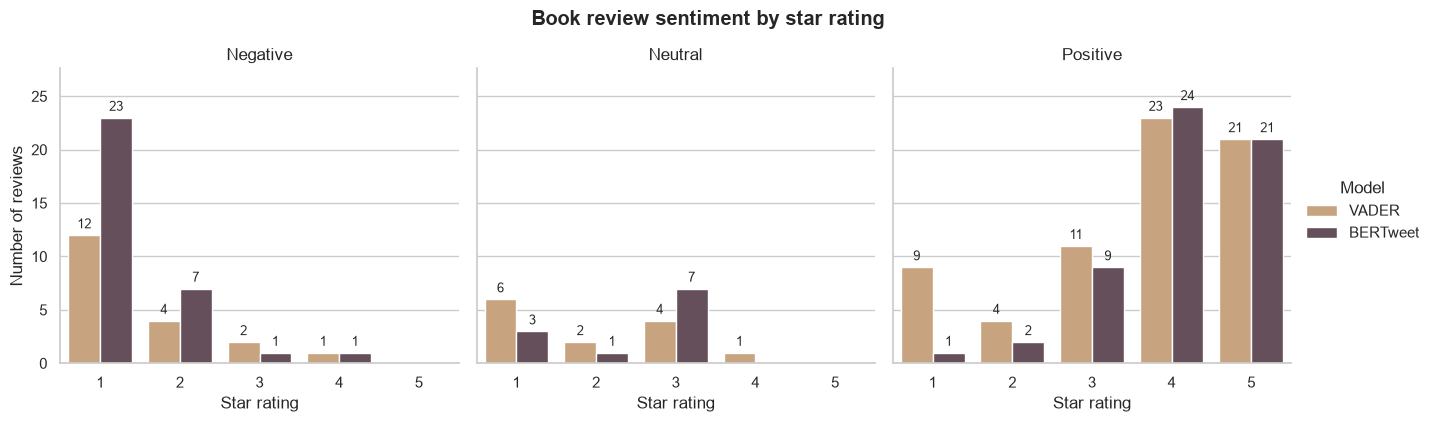

In [17]:
plot_data = data.rename(columns={
    "vader_sentiment_label": "VADER",
    "transformer_sentiment_label": "BERTweet",
}).melt(
    id_vars="rating",
    value_vars=["VADER", "BERTweet"],
    var_name="Model",
    value_name="Sentiment",
)

sns.set_theme(style="whitegrid")

g = sns.catplot(
    data=plot_data,
    kind="count",
    x="rating",
    order=[1, 2, 3, 4, 5],
    hue="Model",
    hue_order=["VADER", "BERTweet"],
    col="Sentiment",
    col_order=["NEG", "NEU", "POS"],
    palette={"VADER": "#D4A373", "BERTweet": "#684C5C"},
    height=4,
    aspect=1.1,
    sharey=True,
)

for ax, title in zip(g.axes.flat, ["Negative", "Neutral", "Positive"]):
    ax.set_title(title)
    ax.margins(y=0.15)
    for bars in ax.containers:
        ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=9)

g.set_axis_labels("Star rating", "Number of reviews")
g.figure.suptitle("Book review sentiment by star rating", y=1.05, fontweight="bold")

Path("assets").mkdir(exist_ok=True)
g.figure.savefig("assets/transformer_vs_vader.png", dpi=300, bbox_inches="tight")
plt.show()

## Takeaway

On this sample of 100 book reviews, BERTweet’s predictions agreed with the sentiment suggested by the star rating in 82 cases, compared with 64 for VADER.

The largest gap appeared among one-star reviews. BERTweet labeled 23 of 27 as negative, while VADER labeled 12 as negative. At the other end of the scale, both models labeled all 21 five-star reviews as positive.

A star rating summarizes the reader’s overall opinion, while the review itself can express mixed feelings. Reading the reviews where the models disagree helps put these counts in context.

<br>